<a href="https://colab.research.google.com/github/Ratmawatii/PIXEL_MAWAR/blob/main/bukti_citra_digital.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#RATMAWATI
#24260013
#PENGOLAHAN CITRA DIGITAL


# Bukti Bahwa Citra Digital = Piksel + Angka
Notebook ini membuktikan secara bertahap bahwa sebuah foto hanyalah **kumpulan angka** yang tersusun dalam grid piksel.

**Alur pembuktian**
1. File foto di disk = deretan **byte** (angka 0-255)
2. Hasil decode = **array 3 dimensi** (tinggi x lebar x kanal RGB)
3. Satu piksel = **3 angka** (R, G, B)
4. Zoom ekstrem = **kotak-kotak** berisi angka
5. Memisah kanal warna = 3 matriks angka terpisah
6. Mengubah angka = gambar berubah
7. **Gambar dibuat dari angka murni** (tanpa foto sama sekali)
8. Foto disimpan sebagai **teks CSV**, lalu dibangun ulang jadi gambar
9. Menampilkan meta data

## 0. Persiapan

In [75]:
import io, os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from google.colab import files

print('NumPy  :', np.__version__)
print('Pillow :', Image.__version__ if hasattr(Image, '__version__') else 'ok')

NumPy  : 2.1.3
Pillow : 11.3.0


## 1. Upload foto
**>>> TEMPAT MEMASUKKAN FOTO <<<** Jalankan sel di bawah, lalu pilih 1 foto dari komputer/HP Anda.

In [76]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [77]:

from google.colab import drive; drive.mount('/content/drive')
NAMA_FILE = '/content/drive/MyDrive/CITRA DIGITAL/20260716_075701.jpg'

print('File dipakai:', NAMA_FILE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
File dipakai: /content/drive/MyDrive/CITRA DIGITAL/20260716_075701.jpg


## 2. Level paling dasar: file foto adalah deretan BYTE
Sebelum jadi gambar, file di disk hanyalah angka 0-255. Awal file berisi *magic number* yang menandai formatnya.

In [78]:
with open(NAMA_FILE, 'rb') as f:
    raw = f.read()

print(f'Ukuran file        : {len(raw):,} byte')
print('32 byte pertama    :', list(raw[:32]))
print('32 byte (heksa)    :', raw[:32].hex(' '))

if raw[:2] == b'\xff\xd8':
    print('Format terdeteksi  : JPEG (magic number FF D8)')
elif raw[:8] == b'\x89PNG\r\n\x1a\n':
    print('Format terdeteksi  : PNG (magic number 89 50 4E 47 ...)')
else:
    print('Format             : lainnya, magic number =', raw[:4].hex(' '))

Ukuran file        : 2,060,358 byte
32 byte pertama    : [255, 216, 255, 225, 255, 124, 69, 120, 105, 102, 0, 0, 73, 73, 42, 0, 8, 0, 0, 0, 20, 0, 0, 1, 3, 0, 1, 0, 0, 0, 240, 15]
32 byte (heksa)    : ff d8 ff e1 ff 7c 45 78 69 66 00 00 49 49 2a 00 08 00 00 00 14 00 00 01 03 00 01 00 00 00 f0 0f
Format terdeteksi  : JPEG (magic number FF D8)


## 3. Decode menjadi array angka
`np.array(gambar)` mengubah foto menjadi matriks. Perhatikan: tipe datanya `ndarray` dan isinya `uint8` (bilangan bulat 0-255).

In [79]:
img = ImageOps.exif_transpose(Image.open(NAMA_FILE)).convert('RGB')  # exif_transpose: koreksi rotasi foto HP
arr = np.array(img)

H, W, C = arr.shape
print('Tipe objek          :', type(arr))
print('Bentuk (shape)      :', arr.shape, '-> tinggi x lebar x kanal')
print('Tipe data (dtype)   :', arr.dtype)
print('Nilai minimum       :', arr.min())
print('Nilai maksimum      :', arr.max())
print()
print(f'Jumlah piksel       : {H} x {W} = {H*W:,} piksel ({H*W/1e6:.2f} megapiksel)')
print(f'Jumlah angka        : {H} x {W} x {C} = {arr.size:,} angka')
print(f'Memori array        : {arr.nbytes:,} byte (1 angka = 1 byte)')
print(f'Ukuran file asli    : {len(raw):,} byte  -> lebih kecil karena dikompresi')

Tipe objek          : <class 'numpy.ndarray'>
Bentuk (shape)      : (4080, 2296, 3) -> tinggi x lebar x kanal
Tipe data (dtype)   : uint8
Nilai minimum       : 0
Nilai maksimum      : 255

Jumlah piksel       : 4080 x 2296 = 9,367,680 piksel (9.37 megapiksel)
Jumlah angka        : 4080 x 2296 x 3 = 28,103,040 angka
Memori array        : 28,103,040 byte (1 angka = 1 byte)
Ukuran file asli    : 2,060,358 byte  -> lebih kecil karena dikompresi


In [80]:
# ---- Bukti jumlah piksel, 4 cara independen ----
H, W, C = arr.shape

# Cara 1: dari shape array
cara1 = H * W

# Cara 2: hitung langsung, 1 baris = berapa piksel, lalu jumlahkan
cara2 = sum(len(baris) for baris in arr)

# Cara 3: jumlah semua angka dibagi 3 kanal
cara3 = arr.size // 3

# Cara 4: dari header file asli (sebelum dikoreksi rotasi)
asli_hdr = Image.open(NAMA_FILE)
lebar_h, tinggi_h = asli_hdr.size
cara4 = lebar_h * tinggi_h

print(f'Cara 1 (shape H x W)            : {cara1:,}')
print(f'Cara 2 (jumlah panjang tiap baris): {cara2:,}')
print(f'Cara 3 (jumlah angka / 3)       : {cara3:,}')
print(f'Cara 4 (header file W x H)      : {cara4:,}  [header: {lebar_h} x {tinggi_h}]')
print()
print('Semua cara sama?        :', cara1 == cara2 == cara3 == cara4)
print(f'Resolusi                : {W} x {H} piksel  =  {cara1/1e6:.2f} megapiksel')
print(f'Jumlah baris (tinggi)   : {H:,}')
print(f'Jumlah kolom (lebar)    : {W:,}')
print(f'Jumlah angka total      : {cara1:,} x 3 = {arr.size:,}')

# Bonus: berapa warna berbeda yang dipakai
warna_unik = len(np.unique(arr.reshape(-1, 3), axis=0))
print(f'Jumlah warna unik       : {warna_unik:,} dari 16.777.216 kemungkinan (256^3)')

Cara 1 (shape H x W)            : 9,367,680
Cara 2 (jumlah panjang tiap baris): 9,367,680
Cara 3 (jumlah angka / 3)       : 9,367,680
Cara 4 (header file W x H)      : 9,367,680  [header: 4080 x 2296]

Semua cara sama?        : True
Resolusi                : 2296 x 4080 piksel  =  9.37 megapiksel
Jumlah baris (tinggi)   : 4,080
Jumlah kolom (lebar)    : 2,296
Jumlah angka total      : 9,367,680 x 3 = 28,103,040
Jumlah warna unik       : 149,275 dari 16.777.216 kemungkinan (256^3)


## 4. Tampilkan gambar dengan sumbu = nomor piksel
Sumbu X dan Y di bawah adalah **indeks kolom dan baris** array, bukan satuan cm/inci.

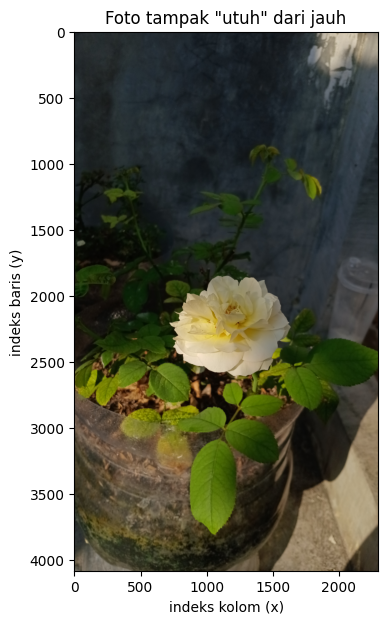

In [81]:
plt.figure(figsize=(7, 7))
plt.imshow(arr)
plt.title('Foto tampak "utuh" dari jauh')
plt.xlabel('indeks kolom (x)'); plt.ylabel('indeks baris (y)')
plt.show()

## 5. Satu piksel = tiga angka (R, G, B)

Piksel [baris=0, kolom=0]  ->  R=29, G=34, B=40   (heksa #1D2228)
Piksel [baris=2040, kolom=1148]  ->  R=153, G=139, B=90   (heksa #998B5A)
Piksel [baris=336, kolom=87]  ->  R=36, G=40, B=41   (heksa #242829)


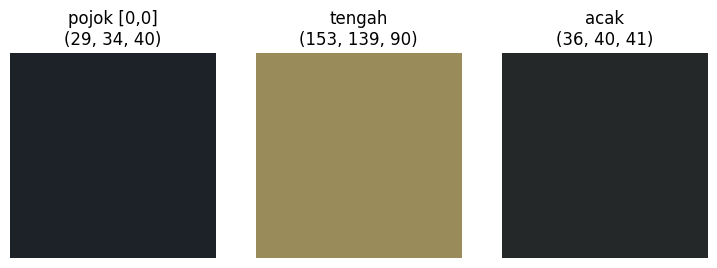

In [82]:
def info_piksel(y, x):
    r, g, b = arr[y, x]
    print(f'Piksel [baris={y}, kolom={x}]  ->  R={r}, G={g}, B={b}   (heksa #{r:02X}{g:02X}{b:02X})')
    return arr[y, x]

p_pojok  = info_piksel(0, 0)
p_tengah = info_piksel(H // 2, W // 2)
p_acak   = info_piksel(np.random.randint(H), np.random.randint(W))

fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for a, p, t in zip(ax, [p_pojok, p_tengah, p_acak], ['pojok [0,0]', 'tengah', 'acak']):
    a.imshow(np.full((10, 10, 3), p, dtype=np.uint8)); a.set_title(f'{t}\n{tuple(int(v) for v in p)}'); a.axis('off')
plt.show()

## 6. Zoom ekstrem: kotak 8x8 piksel beserta angkanya
Setiap kotak adalah satu piksel. Angka di dalamnya adalah nilai R / G / B yang tersimpan di memori.

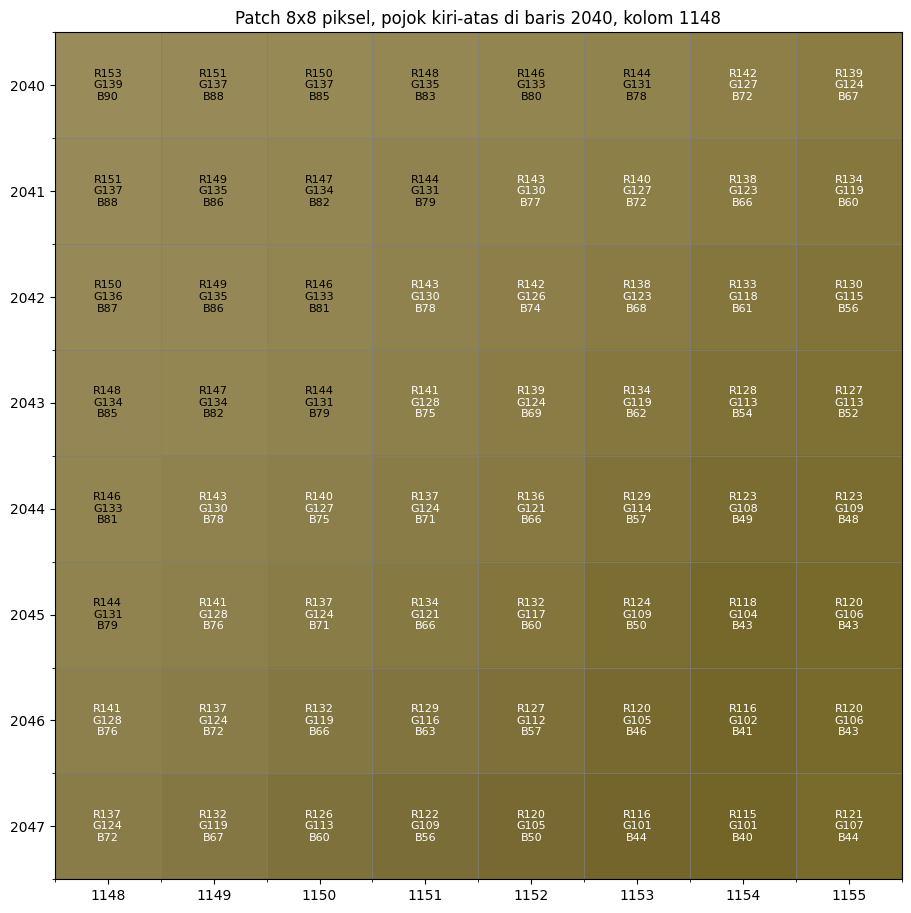

Array mentah patch kanal R (matriks angka):
[[153 151 150 148 146 144 142 139]
 [151 149 147 144 143 140 138 134]
 [150 149 146 143 142 138 133 130]
 [148 147 144 141 139 134 128 127]
 [146 143 140 137 136 129 123 123]
 [144 141 137 134 132 124 118 120]
 [141 137 132 129 127 120 116 120]
 [137 132 126 122 120 116 115 121]]


In [83]:
N = 8
y0, x0 = H // 2, W // 2
patch = arr[y0:y0+N, x0:x0+N]

fig, ax = plt.subplots(figsize=(11, 11))
ax.imshow(patch, interpolation='nearest')
for i in range(patch.shape[0]):
    for j in range(patch.shape[1]):
        r, g, b = patch[i, j]
        lum = 0.299*r + 0.587*g + 0.114*b
        ax.text(j, i, f'R{r}\nG{g}\nB{b}', ha='center', va='center',
                fontsize=8, color='white' if lum < 128 else 'black')
ax.set_xticks(np.arange(N)); ax.set_yticks(np.arange(N))
ax.set_xticklabels(np.arange(x0, x0+N)); ax.set_yticklabels(np.arange(y0, y0+N))
ax.set_xticks(np.arange(-.5, N), minor=True); ax.set_yticks(np.arange(-.5, N), minor=True)
ax.grid(which='minor', color='gray', linewidth=0.5)
ax.set_title(f'Patch {N}x{N} piksel, pojok kiri-atas di baris {y0}, kolom {x0}')
plt.show()

print('Array mentah patch kanal R (matriks angka):')
print(patch[:, :, 0])

## 7. Efek pikselasi: perbesar crop 16x16
Saat dibesarkan **tanpa interpolasi**, tampak jelas bahwa gambar tersusun dari kotak berwarna tunggal.

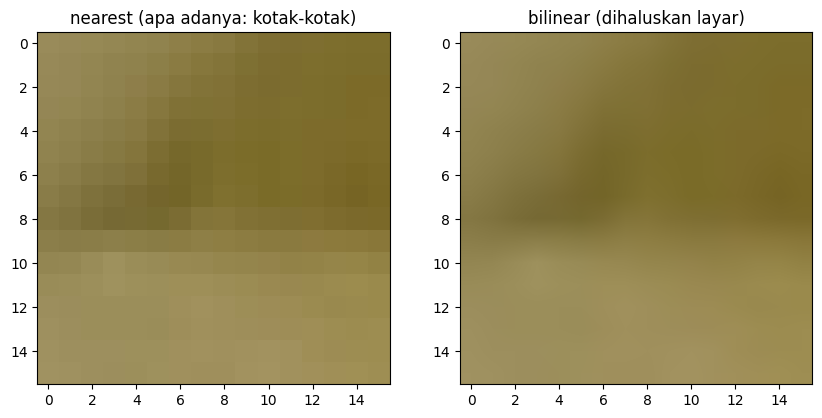

In [84]:
crop16 = arr[y0:y0+16, x0:x0+16]
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(crop16, interpolation='nearest'); ax[0].set_title('nearest (apa adanya: kotak-kotak)')
ax[1].imshow(crop16, interpolation='bilinear'); ax[1].set_title('bilinear (dihaluskan layar)')
plt.show()

## 8. Memisah kanal: satu foto = tiga matriks angka
Foto berwarna = tumpukan 3 matriks berukuran sama (Merah, Hijau, Biru).

Bentuk tiap kanal: (4080, 2296) (4080, 2296) (4080, 2296)


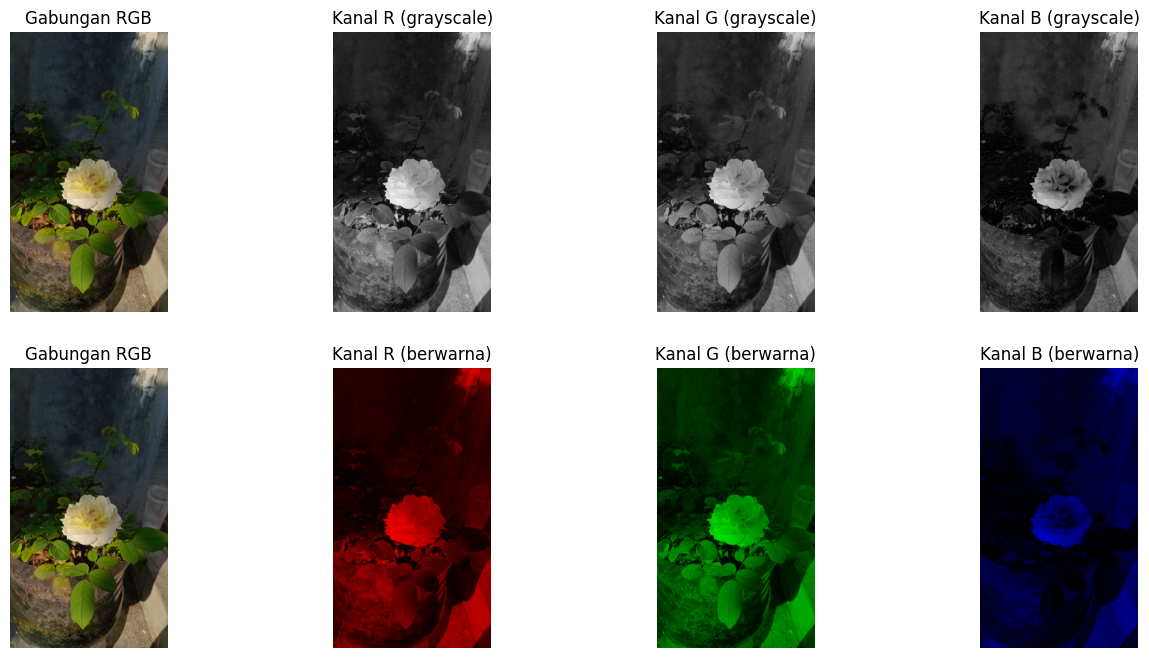

Hasil stack(R,G,B) identik dengan array asli? -> True


In [85]:
R, G, B = arr[:, :, 0], arr[:, :, 1], arr[:, :, 2]
print('Bentuk tiap kanal:', R.shape, G.shape, B.shape)

def tint(kanal, idx):
    z = np.zeros_like(arr); z[:, :, idx] = kanal; return z

fig, ax = plt.subplots(2, 4, figsize=(16, 8))
ax[0, 0].imshow(arr); ax[0, 0].set_title('Gabungan RGB')
for k, (nm, ch) in enumerate([('R', R), ('G', G), ('B', B)], start=1):
    ax[0, k].imshow(ch, cmap='gray', vmin=0, vmax=255); ax[0, k].set_title(f'Kanal {nm} (grayscale)')
ax[1, 0].imshow(arr); ax[1, 0].set_title('Gabungan RGB')
for k, (nm, ch, i) in enumerate([('R', R, 0), ('G', G, 1), ('B', B, 2)], start=1):
    ax[1, k].imshow(tint(ch, i)); ax[1, k].set_title(f'Kanal {nm} (berwarna)')
for a in ax.ravel(): a.axis('off')
plt.show()

# Bukti: menumpuk kembali 3 matriks menghasilkan array yang IDENTIK
gabung = np.stack([R, G, B], axis=-1)
print('Hasil stack(R,G,B) identik dengan array asli? ->', np.array_equal(gabung, arr))

## 9. Grayscale = rumus matematika atas angka
Grayscale adalah kombinasi berbobot dari R, G, B. Kita hitung manual dan bandingkan dengan fungsi bawaan Pillow.

Selisih maksimum manual vs Pillow : 1 (selisih kecil = beda pembulatan internal)
Selisih rata-rata                 : 0.0
Bentuk array grayscale            : (4080, 2296) (2 dimensi, 1 angka per piksel)


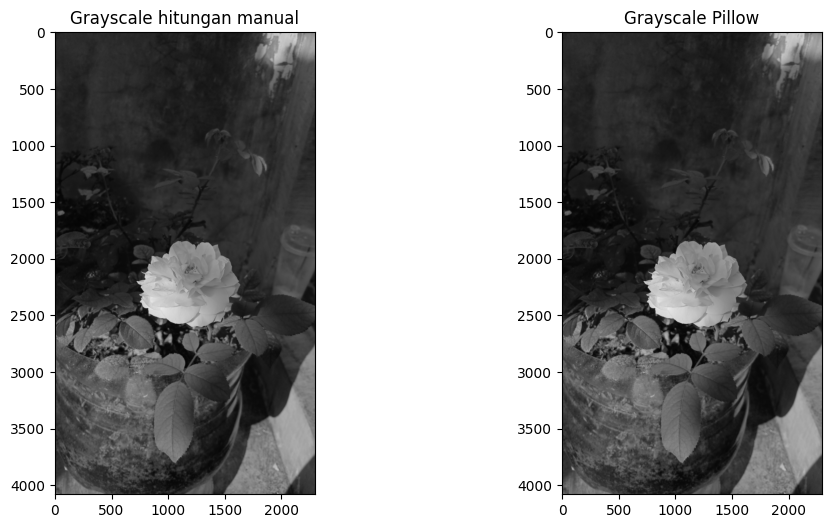

In [86]:
gray_manual = (0.299*R + 0.587*G + 0.114*B).round().astype(np.uint8)
gray_pil    = np.array(img.convert('L'))
selisih     = np.abs(gray_manual.astype(int) - gray_pil.astype(int))

print('Selisih maksimum manual vs Pillow :', selisih.max(), '(selisih kecil = beda pembulatan internal)')
print('Selisih rata-rata                 :', round(selisih.mean(), 4))
print('Bentuk array grayscale            :', gray_manual.shape, '(2 dimensi, 1 angka per piksel)')

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(gray_manual, cmap='gray', vmin=0, vmax=255); ax[0].set_title('Grayscale hitungan manual')
ax[1].imshow(gray_pil, cmap='gray', vmin=0, vmax=255);    ax[1].set_title('Grayscale Pillow')
plt.show()

## 10. Histogram: distribusi angka pada foto

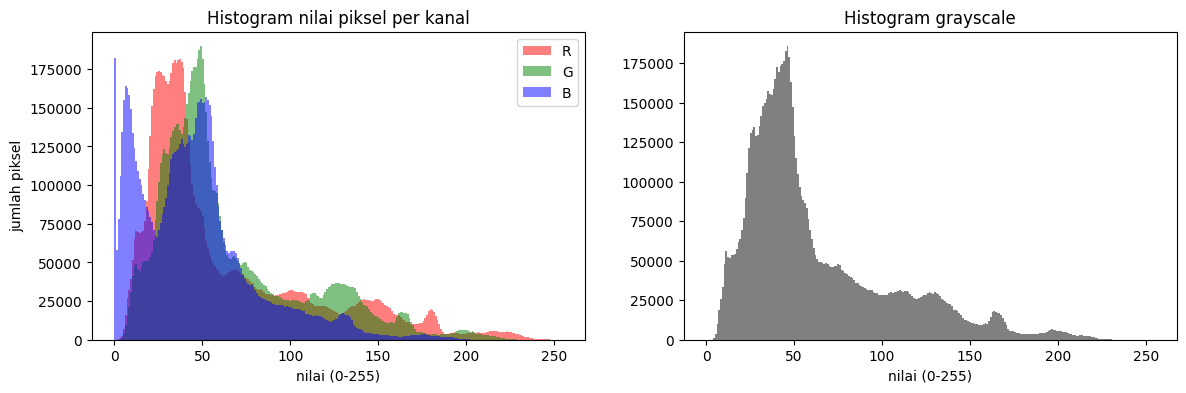

Statistik per kanal:
  R: min=  0  max=255  rata-rata=  63.49  std= 49.28
  G: min=  1  max=238  rata-rata=  65.37  std= 42.49
  B: min=  0  max=210  rata-rata=  45.76  std= 34.26


In [87]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for ch, warna, nm in [(R, 'red', 'R'), (G, 'green', 'G'), (B, 'blue', 'B')]:
    ax[0].hist(ch.ravel(), bins=256, range=(0, 255), color=warna, alpha=0.5, label=nm)
ax[0].set_title('Histogram nilai piksel per kanal'); ax[0].set_xlabel('nilai (0-255)'); ax[0].set_ylabel('jumlah piksel'); ax[0].legend()
ax[1].hist(gray_manual.ravel(), bins=256, range=(0, 255), color='gray')
ax[1].set_title('Histogram grayscale'); ax[1].set_xlabel('nilai (0-255)')
plt.show()

print('Statistik per kanal:')
for nm, ch in [('R', R), ('G', G), ('B', B)]:
    print(f'  {nm}: min={ch.min():3d}  max={ch.max():3d}  rata-rata={ch.mean():7.2f}  std={ch.std():6.2f}')

## 11. Bukti sebab-akibat: ubah angka, gambar ikut berubah
Jika gambar *hanyalah* angka, maka mengubah angka harus mengubah gambar secara persis sesuai operasi matematikanya.

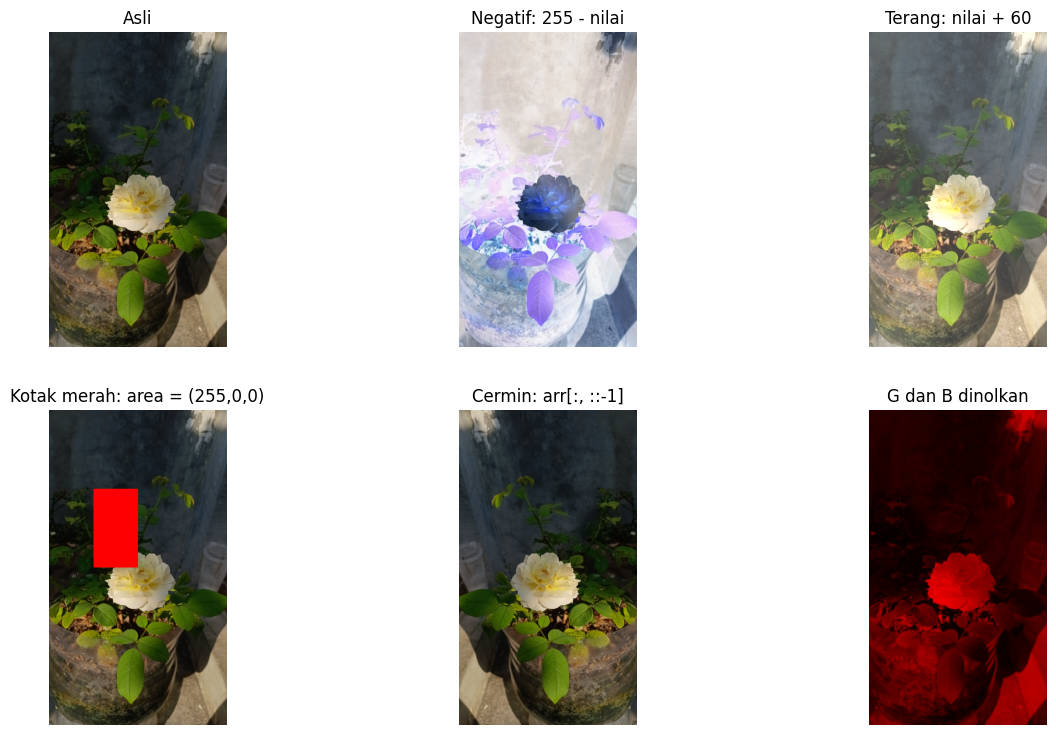

Piksel tengah asli   : [153 139  90]
Piksel tengah negatif: [102 116 165] (harus = 255 - asli)
Verifikasi negatif   : True


In [88]:
negatif  = 255 - arr
terang   = np.clip(arr.astype(int) + 60, 0, 255).astype(np.uint8)
kotak    = arr.copy(); kotak[H//4:H//2, W//4:W//2] = [255, 0, 0]       # timpa area dengan angka (255,0,0)
cermin   = arr[:, ::-1]                                                 # balik urutan kolom
hanya_r  = arr.copy(); hanya_r[:, :, 1:] = 0                           # nolkan G dan B

hasil = [('Asli', arr), ('Negatif: 255 - nilai', negatif), ('Terang: nilai + 60', terang),
         ('Kotak merah: area = (255,0,0)', kotak), ('Cermin: arr[:, ::-1]', cermin), ('G dan B dinolkan', hanya_r)]

fig, ax = plt.subplots(2, 3, figsize=(15, 9))
for a, (t, g) in zip(ax.ravel(), hasil):
    a.imshow(g); a.set_title(t); a.axis('off')
plt.show()

# Verifikasi numerik pada satu piksel
print('Piksel tengah asli   :', arr[H//2, W//2])
print('Piksel tengah negatif:', negatif[H//2, W//2], '(harus = 255 - asli)')
print('Verifikasi negatif   :', np.array_equal(negatif, 255 - arr))

## 12. Bukti paling kuat: membuat gambar dari angka murni (tanpa foto)
Jika angka bisa jadi gambar tanpa kamera, maka gambar memang hanya angka.

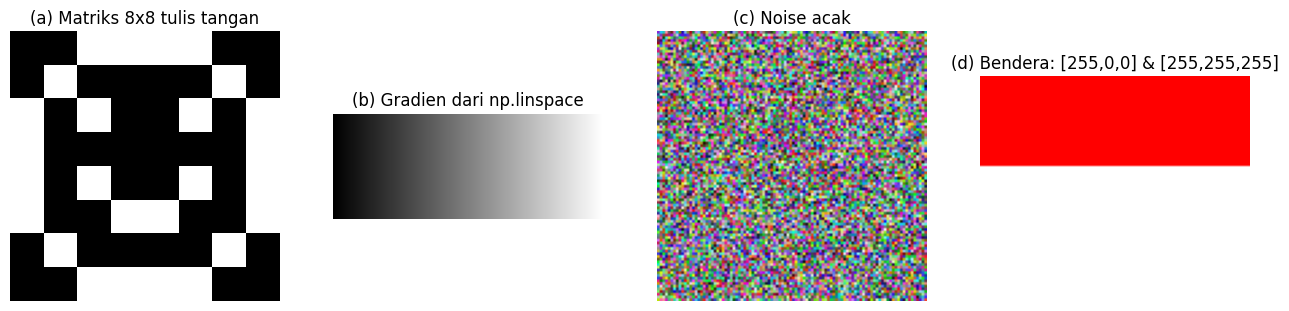

Matriks smiley (inilah "gambar" tersebut):
[[  0   0 255 255 255 255   0   0]
 [  0 255   0   0   0   0 255   0]
 [255   0 255   0   0 255   0 255]
 [255   0   0   0   0   0   0 255]
 [255   0 255   0   0 255   0 255]
 [255   0   0 255 255   0   0 255]
 [  0 255   0   0   0   0 255   0]
 [  0   0 255 255 255 255   0   0]]


In [89]:
# (a) Gambar 8x8 yang ditulis tangan sebagai matriks 0/1
smiley = np.array([
    [0,0,1,1,1,1,0,0],
    [0,1,0,0,0,0,1,0],
    [1,0,1,0,0,1,0,1],
    [1,0,0,0,0,0,0,1],
    [1,0,1,0,0,1,0,1],
    [1,0,0,1,1,0,0,1],
    [0,1,0,0,0,0,1,0],
    [0,0,1,1,1,1,0,0]], dtype=np.uint8) * 255

# (b) Gradien: nilai naik dari 0 ke 255 per kolom
gradien = np.tile(np.linspace(0, 255, 256), (100, 1)).astype(np.uint8)

# (c) Noise acak RGB
rng = np.random.default_rng(42)
noise = rng.integers(0, 256, size=(100, 100, 3), dtype=np.uint8)

# (d) Bendera Indonesia: 2 baris warna, dibuat dari angka
bendera = np.zeros((60, 90, 3), dtype=np.uint8)
bendera[:30] = [255, 0, 0]
bendera[30:] = [255, 255, 255]

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
ax[0].imshow(smiley, cmap='gray', interpolation='nearest'); ax[0].set_title('(a) Matriks 8x8 tulis tangan')
ax[1].imshow(gradien, cmap='gray', vmin=0, vmax=255);       ax[1].set_title('(b) Gradien dari np.linspace')
ax[2].imshow(noise);                                        ax[2].set_title('(c) Noise acak')
ax[3].imshow(bendera);                                      ax[3].set_title('(d) Bendera: [255,0,0] & [255,255,255]')
for a in ax: a.axis('off')
plt.show()

print('Matriks smiley (inilah "gambar" tersebut):')
print(smiley)

## 13. Round-trip: array -> file -> array
**PNG** (lossless) harus mengembalikan angka yang persis sama. **JPEG** (lossy) tidak, karena membuang sebagian informasi.

In [90]:
# PNG: lossless
buf = io.BytesIO(); Image.fromarray(arr).save(buf, format='PNG'); buf.seek(0)
dari_png = np.array(Image.open(buf).convert('RGB'))
print('PNG  - ukuran file :', f'{buf.getbuffer().nbytes:,} byte')
print('PNG  - angka identik dengan asli? ->', np.array_equal(arr, dari_png))

# JPEG kualitas rendah: lossy
for q in (95, 50, 10):
    buf = io.BytesIO(); Image.fromarray(arr).save(buf, format='JPEG', quality=q); buf.seek(0)
    dari_jpg = np.array(Image.open(buf).convert('RGB'))
    err = np.abs(arr.astype(int) - dari_jpg.astype(int))
    print(f'JPEG q={q:2d} - ukuran {buf.getbuffer().nbytes:>10,} byte | identik? {np.array_equal(arr, dari_jpg)!s:5} | selisih rata-rata {err.mean():.3f} | maks {err.max()}')

PNG  - ukuran file : 5,827,925 byte
PNG  - angka identik dengan asli? -> True
JPEG q=95 - ukuran  1,572,867 byte | identik? False | selisih rata-rata 0.341 | maks 21
JPEG q=50 - ukuran    307,468 byte | identik? False | selisih rata-rata 1.406 | maks 49
JPEG q=10 - ukuran    176,184 byte | identik? False | selisih rata-rata 4.825 | maks 74


## 14. Foto sebagai file TEKS: simpan angka ke CSV, bangun ulang jadi gambar
Bukti akhir: tanpa file gambar sama sekali, hanya teks berisi angka, kita bisa merekonstruksi gambar yang sama.

Isi 8 baris pertama piksel.csv:
['R,G,B', '153,139,90', '151,137,88', '150,137,85', '148,135,83', '146,133,80', '144,131,78', '142,127,72']
Jumlah baris data: 1024 (= 32 x 32 piksel)
Hasil bangun ulang identik dengan potongan asli? -> True


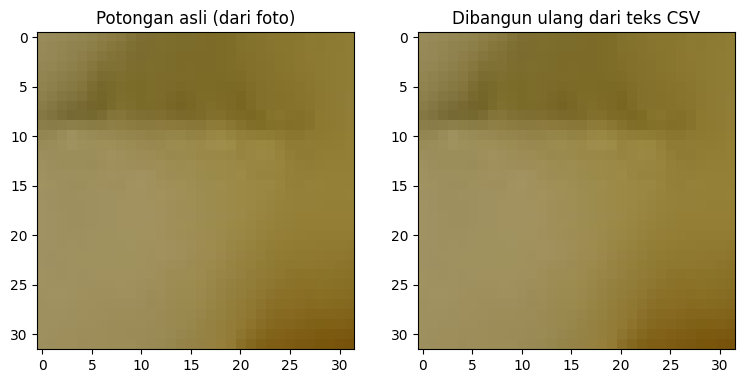

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [91]:
S = min(32, H, W)
potongan = arr[y0:y0+S, x0:x0+S] if (y0+S <= H and x0+S <= W) else arr[:S, :S]

np.savetxt('piksel.csv', potongan.reshape(-1, 3), fmt='%d', delimiter=',', header='R,G,B', comments='')
print('Isi 8 baris pertama piksel.csv:')
print(open('piksel.csv').read().splitlines()[:8])
print(f'Jumlah baris data: {S*S} (= {S} x {S} piksel)')

dari_csv = np.loadtxt('piksel.csv', delimiter=',', skiprows=1, dtype=np.uint8).reshape(S, S, 3)
print('Hasil bangun ulang identik dengan potongan asli? ->', np.array_equal(dari_csv, potongan))

fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
ax[0].imshow(potongan, interpolation='nearest'); ax[0].set_title('Potongan asli (dari foto)')
ax[1].imshow(dari_csv, interpolation='nearest'); ax[1].set_title('Dibangun ulang dari teks CSV')
plt.show()

files.download('piksel.csv')   # opsional: unduh untuk dilampirkan di repo

## 15. Ringkasan bukti

In [92]:
bukti = [
    ('File = deretan byte (ada magic number)',                         raw[:2] in (b'\xff\xd8', b'\x89P')),
    ('Decode menghasilkan ndarray bertipe uint8 0-255',                arr.dtype == np.uint8 and arr.min() >= 0 and arr.max() <= 255),
    ('Jumlah angka = tinggi x lebar x 3',                              arr.size == H * W * 3),
    ('Stack kanal R,G,B == array asli',                                np.array_equal(np.stack([R, G, B], -1), arr)),
    ('Negatif = 255 - angka (terverifikasi)',                          np.array_equal(negatif, 255 - arr)),
    ('PNG round-trip identik (lossless)',                              np.array_equal(arr, dari_png)),
    ('Gambar dibangun ulang dari CSV identik',                         np.array_equal(dari_csv, potongan)),
]
for k, v in bukti:
    print(('[LULUS] ' if v else '[GAGAL] ') + k)

[LULUS] File = deretan byte (ada magic number)
[LULUS] Decode menghasilkan ndarray bertipe uint8 0-255
[LULUS] Jumlah angka = tinggi x lebar x 3
[LULUS] Stack kanal R,G,B == array asli
[LULUS] Negatif = 255 - angka (terverifikasi)
[LULUS] PNG round-trip identik (lossless)
[LULUS] Gambar dibangun ulang dari CSV identik


In [93]:
from PIL import ExifTags

TAMPILKAN_GPS = False   # ubah ke True hanya untuk dilihat sendiri; JANGAN commit output berisi GPS ke GitHub publik

asli = Image.open(NAMA_FILE)   # dibuka ulang (tanpa exif_transpose) agar metadata tidak berubah

# ---------- A. Info dasar dari header file ----------
print('=== A. INFO DASAR (header file) ===')
print('Format       :', asli.format)
print('Mode warna   :', asli.mode)
print('Ukuran       :', asli.size, '(lebar x tinggi)')
print('DPI          :', asli.info.get('dpi', 'tidak ada'))
print('Ukuran file  :', os.path.getsize(NAMA_FILE), 'byte')

def rapikan(v):
    if isinstance(v, bytes):
        return f'<{len(v)} byte biner>'
    s = str(v)
    return s if len(s) <= 80 else s[:80] + '...'

# ---------- B. EXIF utama (IFD0) ----------
exif = asli.getexif()
print('\n=== B. EXIF UTAMA ===')
if not exif:
    print('Tidak ada EXIF. Kemungkinan foto sudah dikirim lewat WhatsApp/medsos yang menghapus metadata.')
for tag_id, nilai in exif.items():
    print(f'{ExifTags.TAGS.get(tag_id, tag_id):<22}: {rapikan(nilai)}')

# ---------- C. EXIF kamera (pengaturan pemotretan) ----------
print('\n=== C. DETAIL KAMERA (Exif IFD) ===')
try:
    detail = exif.get_ifd(0x8769)
except Exception:
    detail = {}
if not detail:
    print('(kosong)')
for tag_id, nilai in detail.items():
    print(f'{ExifTags.TAGS.get(tag_id, tag_id):<22}: {rapikan(nilai)}')

# ---------- D. GPS ----------
print('\n=== D. GPS ===')
try:
    gps = exif.get_ifd(0x8825)
except Exception:
    gps = {}
if not gps:
    print('Tidak ada data GPS.')
elif not TAMPILKAN_GPS:
    print(f'Ada {len(gps)} field GPS di foto ini, disembunyikan demi privasi (TAMPILKAN_GPS = False).')
else:
    for tag_id, nilai in gps.items():
        print(f'{ExifTags.GPSTAGS.get(tag_id, tag_id):<22}: {rapikan(nilai)}')

# ---------- E. Bukti: metadata TERPISAH dari piksel ----------
print('\n=== E. METADATA vs PIKSEL ===')
buf = io.BytesIO(); Image.fromarray(arr).save(buf, format='PNG'); buf.seek(0)
bersih = Image.open(buf)
print('Jumlah tag EXIF di file asli           :', len(exif))
print('Jumlah tag EXIF setelah array->PNG     :', len(bersih.getexif()))
print('Piksel tetap sama persis?              :', np.array_equal(np.array(bersih.convert("RGB")), arr))
print('Kesimpulan: metadata bukan bagian dari array piksel; ia dibuang saat array disimpan ulang.')

=== A. INFO DASAR (header file) ===
Format       : JPEG
Mode warna   : RGB
Ukuran       : (4080, 2296) (lebar x tinggi)
DPI          : (72.0, 72.0)
Ukuran file  : 2060358 byte

=== B. EXIF UTAMA ===
ImageWidth            : 4080
ImageLength           : 2296
ImageDescription      :                                
Make                  : samsung                        
Model                 : Galaxy A15 5G                  
Orientation           : 6
YCbCrPositioning      : 2
XResolution           : 72.0
YResolution           : 72.0
544                   : 0
545                   : 0
546                   : 0
547                   : 0
548                   : 0
549                   :                                
GPSInfo               : 952
ResolutionUnit        : 2
Software              : MediaTek Camera Application    
DateTime              : 2026:07:16 07:57:02
ExifOffset            : 450

=== C. DETAIL KAMERA (Exif IFD) ===
ExifVersion           : <4 byte biner>
ComponentsConfigurati

## Kesimpulan
Foto digital **bukan** objek visual di tingkat penyimpanannya, melainkan:

- **Piksel**: elemen terkecil berupa kotak bernilai tunggal
- **Angka**: tiap piksel menyimpan 3 bilangan bulat 0-255 (R, G, B)
- **Struktur**: grid 2D x 3 kanal (tinggi x lebar x 3)
- **Operasi gambar = operasi matematika** pada angka (negatif, terang, cermin, grayscale)
- **Gambar bisa dibuat tanpa kamera**, cukup dari matriks angka

**Batasan yang jujur:** notebook ini membuktikan hal tersebut pada citra raster (JPEG/PNG). Gambar vektor (SVG) disimpan sebagai rumus bentuk, bukan grid piksel. Format lossy seperti JPEG menyimpan koefisien kompresi, bukan piksel langsung; piksel baru muncul setelah di-decode.